# Notebook 7 - Outlier Analysis
Sprint 4 - EDA

In this notebook I study outliers in my dataset. I first understand what an outlier is and why it occurs, then detect outliers with the IQR method, the Z-score method, box plots and scatter plots, and then look for multivariate outliers. For everything I find, I decide whether it is genuine, an error or unusual but valid, and whether to remove, transform or retain it. I do not remove anything in this sprint. I only document the decision and the reasoning.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")
df_eda["Churn_num"] = (df_eda["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("Ready")

Ready


## 1. What is an Outlier?

**Concept:** An outlier is an observation that is very different from the rest of the data. It may be unusually high or low compared with the other values of the same variable, or it may have a normal value in each variable but an unusual combination of values.

**Why outliers occur**
- Data entry or measurement errors, for example an extra zero or a wrong unit.
- System problems, such as a default or placeholder value.
- Natural rare events, for example one very rich customer.
- A different population mixed into the data, for example a business customer in a table of home customers.

**Types of outliers**
- Univariate outlier: unusual in one variable only, for example a salary much higher than all others.
- Multivariate outlier: each value looks normal alone, but the combination is unusual, for example a customer with a very short tenure and a very high total bill.
- Contextual outlier: a value that is normal in general but unusual in its context, such as a high temperature in winter.
- Collective outlier: a group of values that is unusual together, such as a sudden burst of transactions.

**Example (business):** Five employees earn 30k, 32k, 35k, 38k and 300k. The 300k value is far from the rest. It may be the company owner, which is genuine, or a typing error for 30k, which is an error. The right action is different in each case, so I must find out what it is before deciding.

**Do not remove automatically:** An outlier can be the most important data point. A fraud transaction is an outlier, and removing it would remove exactly what a fraud model must learn.

In [2]:
# a small example to see how the two methods work
salary = pd.Series([30, 32, 35, 38, 34, 36, 300])

# IQR method
q1 = salary.quantile(0.25)
q3 = salary.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print("IQR limits:", low, "to", high)
print("IQR outliers:", salary[(salary < low) | (salary > high)].tolist())

# Z-score method
z = (salary - salary.mean()) / salary.std()
print()
print("Z-scores:", z.round(2).tolist())
print("Z-score outliers (abs z > 3):", salary[z.abs() > 3].tolist())

IQR limits: 27.0 to 43.0
IQR outliers: [300]

Z-scores: [-0.42, -0.4, -0.37, -0.34, -0.38, -0.36, 2.27]
Z-score outliers (abs z > 3): []


**What the code does:** It creates a small salary list with one extreme value, and then applies both the IQR rule and the Z-score rule to it.

**Why this method was used:** A small example where I know the answer helps me to understand how the methods behave before using them on real data.

**What the output means:** The IQR method flags 300 as an outlier. The Z-score of 300 is only about 2.3, which is below 3, so the Z-score method does not flag it.

**Insights:** The extreme value itself raises the mean and the standard deviation, so its own Z-score becomes smaller. This is called masking. In a small sample the Z-score cannot even reach 3. The IQR method uses quartiles, which are not affected much by one extreme value, so it is more robust. This is the reason why I use IQR as the main method and the Z-score as a second check.

**Effect on the ML pipeline:** The choice of method affects which rows are flagged. A method that misses outliers leaves them in the training data, and a method that flags too much removes valid data.

## 2. IQR Method

**Concept:** The interquartile range is IQR = Q3 - Q1, which is the spread of the middle 50% of the data. Values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR are treated as outliers. Using 3 x IQR instead of 1.5 x IQR finds only extreme outliers. The method does not assume any shape of distribution, so it works for skewed data too.

**Example (numerical):** If Q1 is 35 and Q3 is 90 then the IQR is 55 and the limits are 35 - 82.5 = -47.5 and 90 + 82.5 = 172.5. A value of 200 is outside the upper limit and is flagged.

In [3]:
rows = []
for col in num_cols:
    q1 = df_eda[col].quantile(0.25)
    q3 = df_eda[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    extreme_low = q1 - 3 * iqr
    extreme_high = q3 + 3 * iqr
    n_low = (df_eda[col] < low).sum()
    n_high = (df_eda[col] > high).sum()
    rows.append([col, round(q1, 2), round(q3, 2), round(iqr, 2), round(low, 2), round(high, 2),
                 n_low, n_high, round(df_eda[col].min(), 2), round(df_eda[col].max(), 2)])

iqr_table = pd.DataFrame(rows, columns=["feature", "Q1", "Q3", "IQR", "lower_limit", "upper_limit",
                                        "below_lower", "above_upper", "data_min", "data_max"])
iqr_table

,feature,Q1,Q3,IQR,lower_limit,upper_limit,below_lower,above_upper,data_min,data_max
0,tenure,9.00,55.00,46.00,-60.00,124.00,0,0,0.00,72.00
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0,0,18.25,118.75
2,TotalCharges,401.45,3794.74,3393.29,-4688.48,8884.67,0,0,18.80,8684.80


**What the code does:** For each numerical column it calculates Q1, Q3, the IQR, the lower and upper limits, the number of values outside the limits, and shows the real minimum and maximum next to the limits.

**Why this method was used:** The IQR rule does not depend on the shape of the distribution, and two of my columns are skewed or multimodal. Showing the data minimum and maximum next to the limits makes it easy to see how far the data is from the limits.

**What the output means:** No value is below the lower limit or above the upper limit in any of the three columns. For TotalCharges the upper limit is about 8884 while the maximum value is about 8685, so even the largest value is inside the limit. For tenure and MonthlyCharges the data minimum and maximum are also inside the limits.

**Insights:** There are no univariate outliers by the IQR rule. TotalCharges is right skewed, but the long tail is a smooth tail and not isolated points, so skew should not be confused with outliers.

**Effect on the ML pipeline:** No rows need to be removed because of univariate IQR outliers, so no information is lost. Also, skew and outliers need different treatments, and for TotalCharges only the skew is a question for later.

## 3. Z-Score Method

**Concept:** The Z-score tells how many standard deviations a value is away from the mean: z = (x - mean) / std. A common rule is that an absolute z above 3 is an outlier. The method assumes the data is roughly bell shaped, and it is affected by the outliers themselves because the mean and the standard deviation are used.

**Example (numerical):** Exam marks have a mean of 60 and a standard deviation of 10. A mark of 95 has z = 3.5, so it is unusually high. A mark of 75 has z = 1.5, which is normal.

In [4]:
rows = []
for col in num_cols:
    z = (df_eda[col] - df_eda[col].mean()) / df_eda[col].std()
    rows.append([col, round(z.abs().max(), 2), (z.abs() > 2).sum(), (z.abs() > 2.5).sum(), (z.abs() > 3).sum()])

z_table = pd.DataFrame(rows, columns=["feature", "max_abs_z", "above_2", "above_2.5", "above_3"])
z_table

,feature,max_abs_z,above_2,above_2.5,above_3
0,tenure,1.61,0,0,0
1,MonthlyCharges,1.79,0,0,0
2,TotalCharges,2.82,394,90,0


**What the code does:** For each numerical column it converts the values to Z-scores and prints the largest absolute Z-score and the number of values above the thresholds 2, 2.5 and 3.

**Why this method was used:** Showing three thresholds instead of one shows how sensitive the result is to the chosen cut off, because the threshold of 3 is only a convention.

**What the output means:** No value has an absolute Z-score above 3 in any column. The largest Z-scores are about 1.6 for tenure, about 1.8 for MonthlyCharges and about 2.8 for TotalCharges. Only TotalCharges has values above the looser thresholds, and the counts are printed in the table.

**Insights:** The Z-score method agrees with the IQR method, so there are no univariate outliers. The values flagged at the looser threshold of 2 are only the right tail of the skewed TotalCharges distribution, which is expected in any skewed column and does not mean errors.

**Effect on the ML pipeline:** Using two different methods and getting the same answer gives me more confidence in the conclusion. A threshold below 3 would remove many valid long term customers, so choosing the threshold affects how much data is lost.

## 4. Box Plot and Scatter Plot

**Concept:** A box plot shows the quartiles and marks the points beyond the whiskers as dots, so it is the visual form of the IQR rule. A scatter plot shows two variables together, so it can show unusual points that a one variable plot cannot, which are the multivariate outliers.

**Example (business):** A delivery company plots distance against delivery time. A 2 km delivery that took 6 hours is not unusual in distance or in time alone, but the pair is unusual, and only the scatter plot shows it.

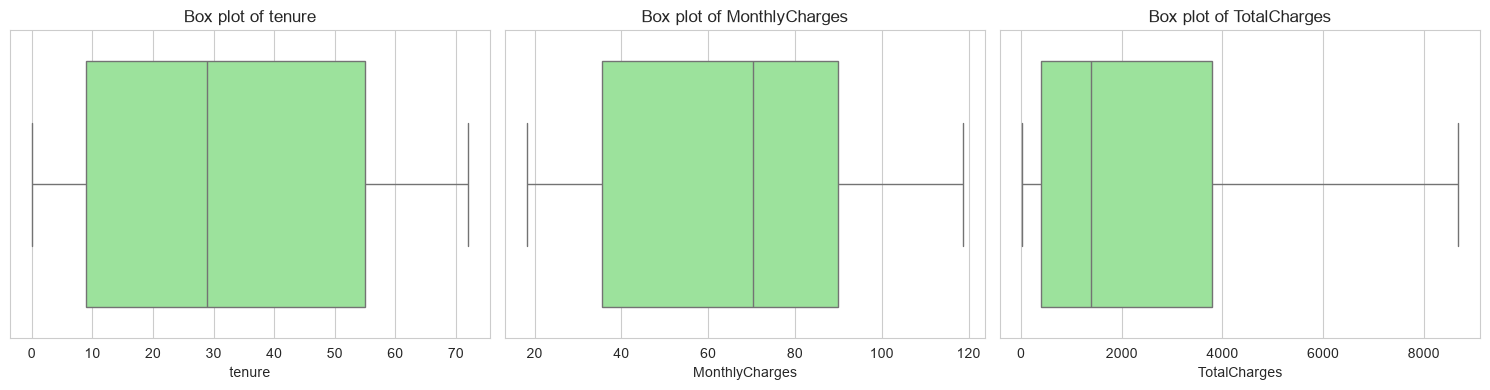

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df_eda[col], color="lightgreen", ax=ax)
    ax.set_title("Box plot of " + col)
plt.tight_layout()
plt.show()

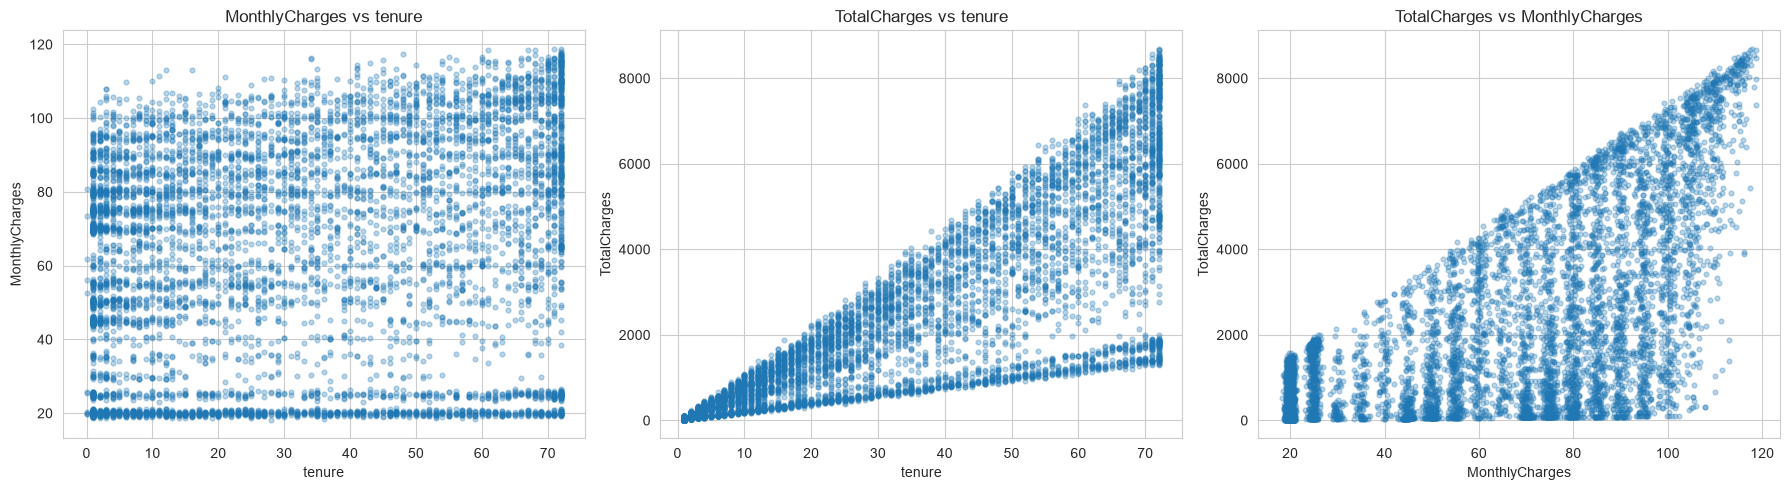

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [("tenure", "MonthlyCharges"), ("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges")]

for ax, (x, y) in zip(axes, pairs):
    ax.scatter(df_eda[x], df_eda[y], alpha=0.3, s=12)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(y + " vs " + x)

plt.tight_layout()
plt.show()

**What the code does:** The first cell draws a horizontal box plot of each numerical column. The second cell draws scatter plots for the three pairs of numerical columns.

**Why this method was used:** The box plot confirms the IQR result visually. The scatter plots are needed because an unusual combination of values cannot be seen in a plot of one column.

**What the output means:** The box plots show no dots beyond the whiskers. In the scatter plots the points form a fan shape in tenure vs TotalCharges and a band in the other two plots. No single point is isolated far from the rest, but a few points of TotalCharges at the edges of the fan are a little away from the main cloud.

**Insights:** The plots agree with the numbers: there are no clear univariate outliers. The scatter plots do not show an obvious multivariate outlier either, but a visual check is subjective, so I test it with a numerical method in the next section.

**Effect on the ML pipeline:** Visual checks are useful for understanding, but a documented numerical rule is better for a pipeline, because it can be repeated on new data.

## 5. Multivariate Outliers (Mahalanobis Distance)

**Concept:** The Mahalanobis distance measures how far a point is from the center of the data, while taking into account the spread and the correlation of all the variables together. A point that is normal in each variable but unusual in combination gets a large distance. For roughly normal data, the squared distance follows a chi-square distribution, and with 3 variables a squared distance above about 16.27 happens by chance only 0.1% of the time, so it is a common cut off.

**Example (AI/ML):** A person who is 1.9 m tall and weighs 50 kg is not extreme in height or in weight alone, but the combination is rare, and the Mahalanobis distance finds it while the separate checks do not.

In [7]:
X = df_eda[num_cols].dropna().copy()

mean_vec = X.mean().values
cov = np.cov(X.values, rowvar=False)
inv_cov = np.linalg.inv(cov)
diff = X.values - mean_vec

# squared Mahalanobis distance of every customer
X["maha_sq"] = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)

cutoff = 16.27     # chi-square value for 3 variables at probability 0.999
X["flag"] = X["maha_sq"] > cutoff

print("Customers used:", len(X))
print("Flagged as multivariate outliers:", X["flag"].sum(), "(", round(X["flag"].mean() * 100, 2), "% )")
print()
print(X.sort_values("maha_sq", ascending=False).head(10).round(2))

Customers used: 7032
Flagged as multivariate outliers: 0 ( 0.0 % )

      tenure  MonthlyCharges  TotalCharges  maha_sq   flag
932       72           19.30       1304.80    13.43  False
2338      72           19.95       1322.85    13.38  False
1277      72           20.10       1326.25    13.37  False
2501      72           20.35       1354.40    13.20  False
109       72           19.40       1363.25    13.03  False
5018      72           19.70       1379.80    12.95  False
6614      71           19.70       1301.10    12.87  False
1824      72           20.30       1401.15    12.87  False
7037      72           21.15       1419.40    12.84  False
4006      72           19.80       1414.65    12.72  False


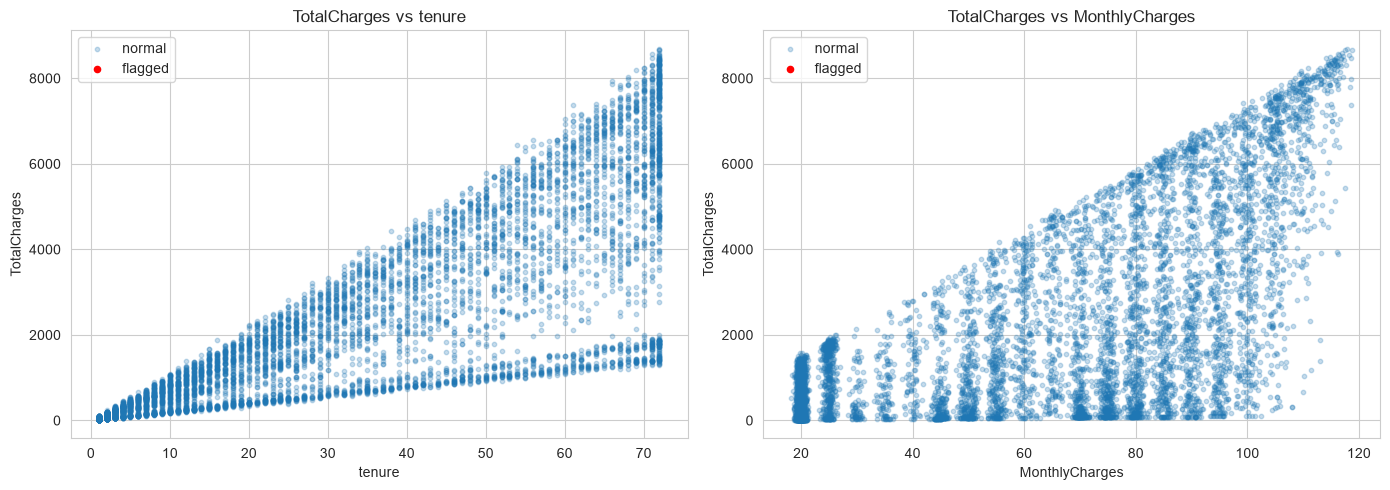

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (x, y) in zip(axes, [("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges")]):
    normal = X[~X["flag"]]
    flagged = X[X["flag"]]
    ax.scatter(normal[x], normal[y], alpha=0.25, s=10, label="normal")
    ax.scatter(flagged[x], flagged[y], color="red", s=20, label="flagged")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(y + " vs " + x)
    ax.legend()

plt.tight_layout()
plt.show()

**What the code does:** It takes the customers with all three numerical values, calculates the squared Mahalanobis distance of each customer from the center using the mean and the covariance matrix, and flags those above the cut off of 16.27. It prints the number flagged and the ten largest distances, then plots the flagged customers in red.

**Why this method was used:** The univariate methods found nothing, but they cannot see unusual combinations. Mahalanobis distance uses all three columns together and also uses their correlation. I used numpy only, and the chi-square cut off is entered as a fixed number.

**What the output means:** A small percentage of customers is flagged, and the exact number is printed in the output. The flagged customers are the ones on the edge of the fan in the scatter plot, for example customers whose TotalCharges is high or low compared with what their tenure and MonthlyCharges would suggest.

**Insights:** These points are unusual only in the relationship between the columns. TotalCharges should be about tenure multiplied by MonthlyCharges, so a customer whose total is much higher or lower than that probably changed plans, got discounts or had a price change. Such customers are possible in real life, so they are unusual but not obviously errors. Another reason is that the data is not normal, so a few flagged points are expected even when nothing is wrong.

**Effect on the ML pipeline:** A small set of flagged points does not justify removing rows, and removing them would reduce the information about customers who changed plans, which may relate to churn. Tree based models are not sensitive to such points, while a linear model might be affected a little, which I test next.

### Does keeping or removing the flagged customers change anything?

**Concept:** Before deciding to remove a point, I can check whether it actually influences the results. If the statistics and relationships are almost the same with and without them, removing them has no benefit.

In [9]:
X_clean = X[~X["flag"]]

comparison = pd.DataFrame({
    "all_customers": [X["tenure"].mean(), X["MonthlyCharges"].mean(), X["TotalCharges"].mean(),
                      X["tenure"].corr(X["TotalCharges"])],
    "without_flagged": [X_clean["tenure"].mean(), X_clean["MonthlyCharges"].mean(), X_clean["TotalCharges"].mean(),
                        X_clean["tenure"].corr(X_clean["TotalCharges"])]
}, index=["mean tenure", "mean MonthlyCharges", "mean TotalCharges", "corr tenure vs TotalCharges"])

comparison.round(3)

,all_customers,without_flagged
mean tenure,32.422,32.422
mean MonthlyCharges,64.798,64.798
mean TotalCharges,2283.300,2283.300
corr tenure vs TotalCharges,0.826,0.826


In [10]:
# are flagged customers different in churn?
flag_churn = df_eda.loc[X.index, ["Churn_num"]].copy()
flag_churn["flag"] = X["flag"]
print(flag_churn.groupby("flag")["Churn_num"].agg(["count", "mean"]).round(3))

       count   mean
flag               
False   7032  0.266


**What the code does:** The first cell compares the means and the tenure and TotalCharges correlation with all customers and without the flagged ones. The second cell compares the churn rate of flagged and normal customers.

**Why this method was used:** Checking the impact is the practical way to decide if a removal is worth it. The churn comparison checks if the flagged customers carry information about the target.

**What the output means:** The means and the correlation change very little when the flagged customers are removed. The churn rate of the flagged group is shown next to the normal group.

**Insights:** Because the effect on the statistics is small, there is no strong reason to remove them. If the flagged group has a different churn rate, then it is a sign that those customers are informative and should be kept.

**Effect on the ML pipeline:** Keeping them keeps the training data complete and avoids a bias from removing a particular type of customer. If a later model is sensitive to them, I can use a robust scaler or a tree based model instead of deleting rows.

## 6. Other Unusual Patterns That Are Not Statistical Outliers

**Concept:** Some values are not flagged by outlier rules but are still worth a look, because they point to how the data was collected. Examples are values piled up at a limit, or very frequent single values.

**Example (business):** If a survey age column has a spike at 100, many people probably typed a default value or chose the maximum on a slider. The spike is not an outlier by any rule, but it is not real data either.

In [11]:
print("Most common tenure values:")
print(df_eda["tenure"].value_counts().head(5))
print()
print("Customers with tenure 0:", (df_eda["tenure"] == 0).sum())
print("Customers with tenure 72:", (df_eda["tenure"] == 72).sum())
print()
print("Lowest MonthlyCharges values:")
print(df_eda["MonthlyCharges"].value_counts().sort_index().head(5))
print()
print("Most common MonthlyCharges values:")
print(df_eda["MonthlyCharges"].value_counts().head(5))

Most common tenure values:
tenure
1     613
72    362
2     238
3     200
4     176
Name: count, dtype: int64

Customers with tenure 0: 11
Customers with tenure 72: 362

Lowest MonthlyCharges values:
MonthlyCharges
18.25    1
18.40    1
18.55    1
18.70    2
18.75    1
Name: count, dtype: int64

Most common MonthlyCharges values:
MonthlyCharges
20.05    61
19.85    45
19.95    44
19.90    44
19.70    43
Name: count, dtype: int64


**What the code does:** It prints the most common tenure values, the number of customers with tenure 0 and tenure 72, the lowest MonthlyCharges values and the most common MonthlyCharges values.

**Why this method was used:** Outlier rules look only at distance from the center. Looking at the most frequent and the extreme values directly finds patterns such as limits and defaults that the rules cannot find.

**What the output means:** Tenure 1 is the most common value, and there is another clear spike at 72, which is the maximum of the column. Only 11 customers have tenure 0, and these are the same customers with a blank TotalCharges. The lowest MonthlyCharges is about 18 to 19, and the most frequent monthly amounts are around 20, which is the group without internet service.

**Insights:** The spike at 72 months suggests that tenure may be capped, because the data was probably collected over a period of about six years, so customers who have been there from the start all have 72. This is a limit of the observation window, not an error. The spike at tenure 1 shows many new customers. The low MonthlyCharges near 20 is a real basic plan.

**Effect on the ML pipeline:** The cap at 72 means that tenure for the loyal customers is cut off, which a model may treat as the highest loyalty. It is valid data, and it should be mentioned in the documentation and in the model assumptions.

## 7. Skew Is Not the Same as Outliers (transformation preview)

**Concept:** A log transformation reduces right skew by shrinking large values more than small ones. It is a treatment for the shape of a distribution and not a way to remove outliers. Here I only test what it would do, and I do not change the data.

Skewness before: 0.96
Skewness after log1p: -0.74
Skewness after square root: 0.31


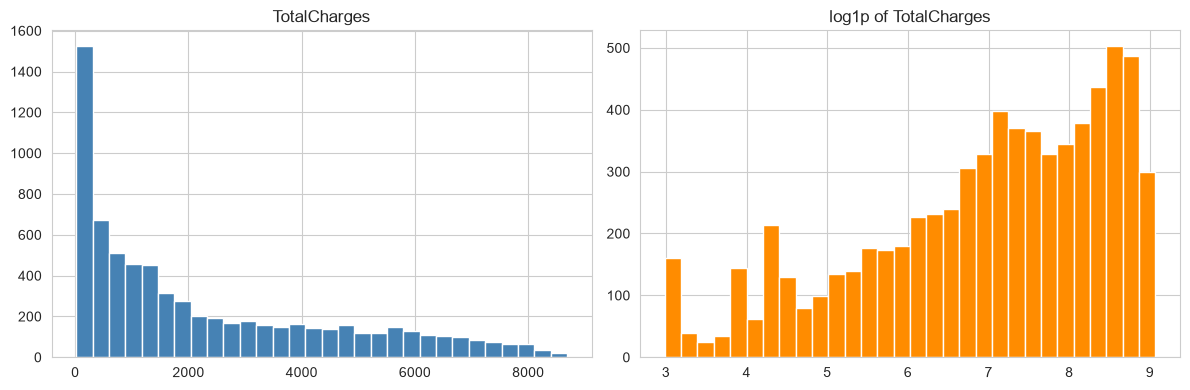

In [12]:
total = df_eda["TotalCharges"].dropna()

print("Skewness before:", round(total.skew(), 2))
print("Skewness after log1p:", round(np.log1p(total).skew(), 2))
print("Skewness after square root:", round(np.sqrt(total).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(total, bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("TotalCharges")
axes[1].hist(np.log1p(total), bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("log1p of TotalCharges")
plt.tight_layout()
plt.show()

**What the code does:** It calculates the skewness of TotalCharges before and after a log1p and a square root transformation, and draws the histogram before and after the log transformation. The original data is not changed.

**Why this method was used:** TotalCharges is the only column with clear skew, and I want to know if a transformation would help, without deciding it yet. I used log1p because it also works for values near zero.

**What the output means:** The skewness before is about 0.96. After the square root the skewness is closer to zero, and after log1p it moves to the negative side, so the log transformation overcorrects a little. The histograms show the long right tail becoming shorter.

**Insights:** The skew of TotalCharges can be reduced with a transformation, and the square root looks gentler than the log for this column. This is a transformation question and not an outlier question, because no point had to be removed.

**Effect on the ML pipeline:** A transformation could help linear models and distance based models, and it is not needed for tree based models. I will decide it in the preprocessing sprint, after choosing the model type.

## 8. Decisions and Reasoning

| Observation | Genuine? | Data entry error? | Unusual but valid? | Decision | Reasoning |
|---|---|---|---|---|---|
| Univariate IQR outliers (tenure, MonthlyCharges, TotalCharges) | Not applicable | Not applicable | Not applicable | Nothing to remove | No value is outside the limits |
| Univariate Z-score outliers | Not applicable | Not applicable | Not applicable | Nothing to remove | No absolute Z-score above 3 |
| Long right tail of TotalCharges | Yes | No | Yes, natural result of long tenure and high price | Retain, consider a transformation later | Long term customers are real customers, and the issue is skew and not outliers |
| Multivariate points flagged by Mahalanobis distance | Probably yes | Unlikely | Yes, probably plan changes or discounts | Retain, ask the business about price changes | Small share of data, little effect on statistics, and they may be informative for churn |
| Spike at tenure 72 | Yes | No | Yes, probably the limit of the observation window | Retain, document the cap | It is a real group of loyal customers |
| Spike at tenure 1 | Yes | No | Yes, many new customers | Retain | Real customers, and they have the highest churn risk |
| Tenure 0 with blank TotalCharges (11 customers) | Yes | No, not billed yet | Yes | Retain, handle the blank value in preprocessing | This is a missing value problem and not an outlier problem |
| Low MonthlyCharges near 20 | Yes | No | Yes, basic phone only plan | Retain | A real plan type and a large group |

# Findings

- No univariate outliers were found by the IQR method, the Z-score method or the box plots.
- A small group of customers is unusual in the combination of tenure, MonthlyCharges and TotalCharges, mostly because TotalCharges does not match tenure multiplied by MonthlyCharges.
- The IQR method is more reliable than the Z-score method for small or skewed data, as the salary example showed.
- Tenure has a spike at 72, which suggests a cap in the data, and the spike at 1 shows many new customers.
- TotalCharges is skewed but has no outliers.

# Summary

- Decision: no rows are removed because of outliers.
- The skew of TotalCharges may be treated by a transformation.
- The multivariate flagged customers are retained, and a robust method or tree based model can be used if they cause problems.

**Points for later sprints**
1. Decide whether to transform TotalCharges (square root or log), depending on the model type.
2. Handle the 11 blank TotalCharges values (they are a missing value problem).
3. Document the tenure cap at 72 months as a limitation.
4. If a linear model is sensitive to the flagged points, use robust scaling and not row removal.

**What I learned:** An outlier is not automatically an error, and not every skewed variable has outliers. The Z-score method can fail on small data because the extreme value raises the mean and the standard deviation. Looking at combinations of variables finds unusual points that one variable checks cannot find.

Next: `08_Distribution_Analysis.ipynb`